In [1]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from collections import Counter

In [31]:
model = YOLO("yolov8n.pt")

image_path = "../data/retail/retail.jpg"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError("Retail image not found.")

In [32]:
TARGET_CLASSES = {
    39: "bottle",
    47: "apple"
}

In [33]:
TARGET_CLASSES = {
    39: "bottle",
    46: "banana",
    47: "apple",
    49: "orange"
}

In [34]:
results = model(image, verbose=False)

result = results[0]

In [35]:
CONFIDENCE_THRESHOLD = 0.50

output = image.copy()

counts = Counter()

In [36]:
for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    if (
        class_id in TARGET_CLASSES
        and confidence >= CONFIDENCE_THRESHOLD
    ):
        x1, y1, x2, y2 = map(
            int,
            box.xyxy[0].cpu().numpy()
        )

        class_name = TARGET_CLASSES[class_id]

        counts[class_name] += 1

        cv2.rectangle(
            output,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        label = f"{class_name}: {confidence:.2f}"

        cv2.putText(
            output,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

In [37]:
total_count = sum(counts.values())

print("Detected target items:", dict(counts))
print("Total target item count:", total_count)

Detected target items: {'bottle': 31, 'apple': 1, 'orange': 1}
Total target item count: 33


In [38]:
banner_text = f"Target Item Count: {total_count}"

cv2.rectangle(
    output,
    (0, 0),
    (output.shape[1], 60),
    (0, 0, 0),
    -1
)

cv2.putText(
    output,
    banner_text,
    (20, 40),
    cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (255, 255, 255),
    2
)

array([[[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       ...,

       [[ 60,  58,  57],
        [ 59,  56,  55],
        [ 58,  55,  55],
        ...,
        [185, 194, 208],
        [205, 217, 227],
        [207, 220, 229]],

       [[ 59,  55,  56],
        [ 57,  54,  53],
        [ 57,  54,  54],
        ...,
        [170, 181, 197],
        [198, 213, 224],
        [204, 218, 229]],

       [[ 61,  57,  59],
        [ 59,  55,  57],
        [ 58,  54,  56],
        ...,
        [175, 189, 203],
        [174, 186, 203],
        [186, 199, 212]]

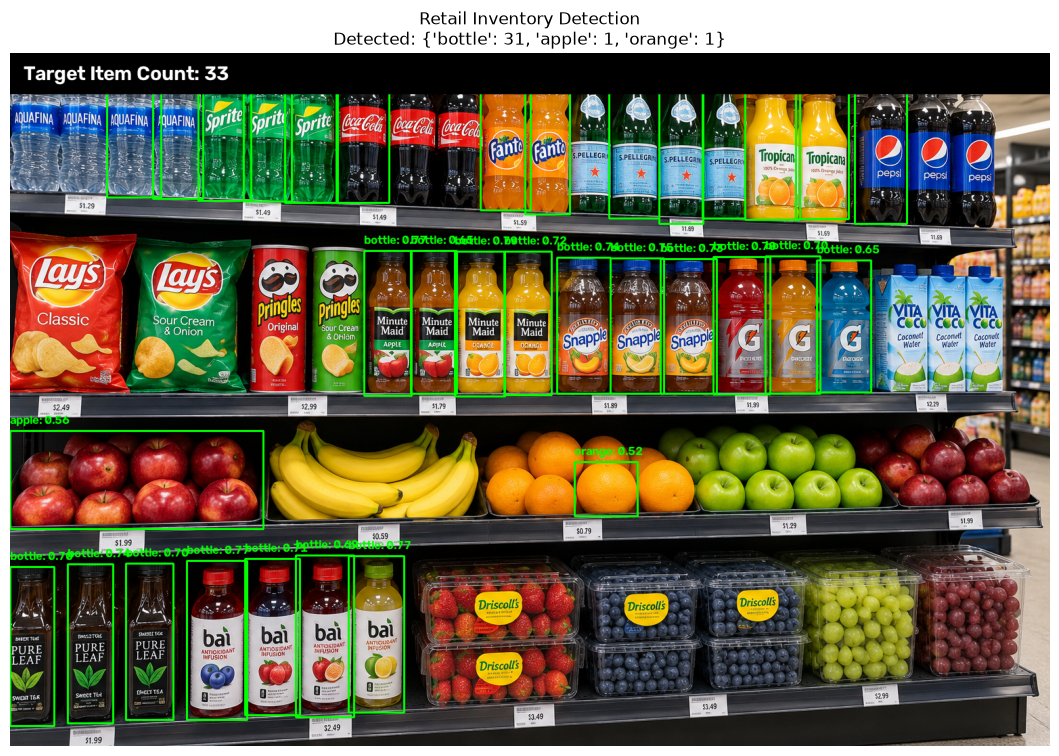

In [39]:
output_rgb = cv2.cvtColor(
    output,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(14, 9))

plt.imshow(output_rgb)

plt.title(
    f"Retail Inventory Detection\n"
    f"Detected: {dict(counts)}"
)

plt.axis("off")
plt.show()

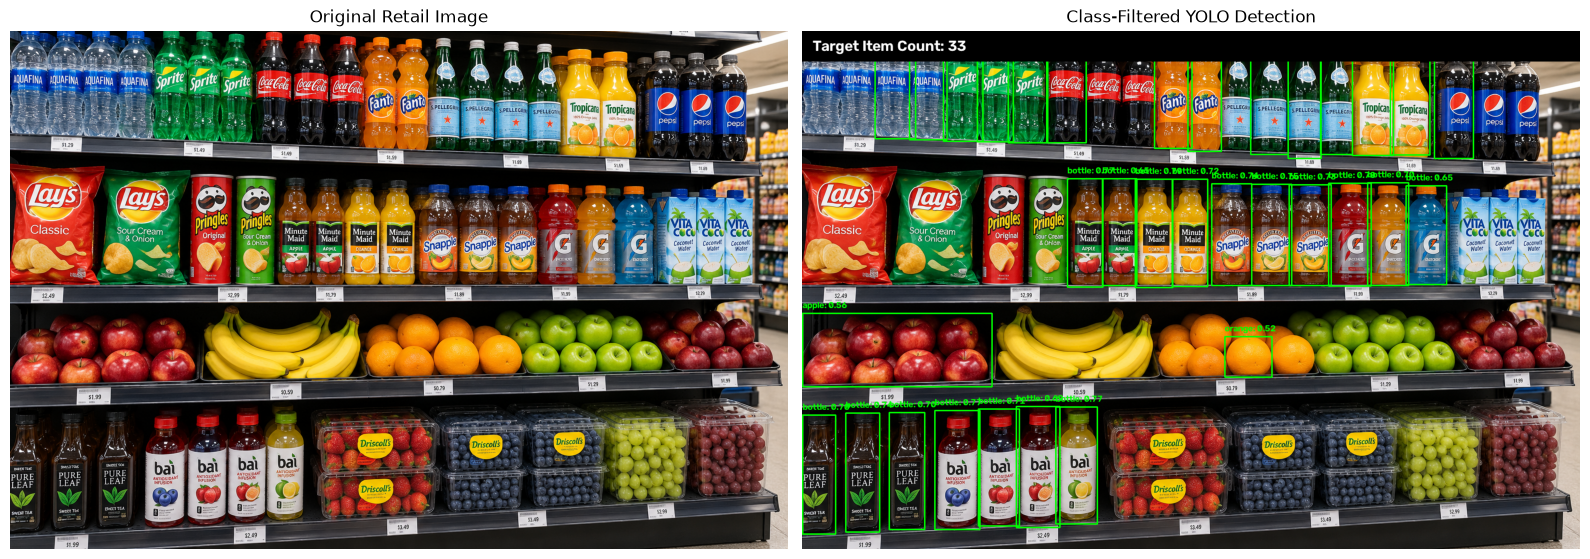

In [40]:
original_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Retail Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_rgb)
plt.title("Class-Filtered YOLO Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

In [41]:
cv2.imwrite(
    "../outputs/task5/retail_detection.jpg",
    output
)

print("Saved to outputs/task5/retail_detection.jpg")

Saved to outputs/task5/retail_detection.jpg
